In [2]:
from pathlib import Path
import numpy as np
import mne
import json
import os
from glob import glob
import pandas as pd
import re
from collections import defaultdict
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from mne_connectivity import spectral_connectivity_epochs
import ptitprince as pt
import matplotlib.pyplot as plt

In [9]:
#simulate simple EEG data, two electrodes, 4 epochs, 7 examples of different phase differences 
sfreq = 250          #Sampling frequency (Hz)
duration = 4.0       #Seconds per epoch
freq = 10.0          #Alpha frequency (Hz)
t = np.arange(0, duration, 1 / sfreq)

#Phase differences (degrees) for the four epochs in each example
examples = {
    "Example 1": [90, 90, 90, 90],
    "Example 2": [45, 45, 45, 45],
    "Example 3": [30, 45, 75, 90],
    "Example 4": [45, 90, 150, 195],
    "Example 5": [90, -90, 90, -90],
    "Example 6": [30, 60, -45, -45],
    "Example 7": [-60, -90, -90, -120],
}

info = mne.create_info(
    ch_names=["A", "B"],
    sfreq=sfreq,
    ch_types=["eeg", "eeg"]
)

simulated_epochs = {}

for name, phase_differences in examples.items():
    data = []

    for phase_deg in phase_differences:
        phase_rad = np.deg2rad(phase_deg)

        signal_a = np.sin(2 * np.pi * freq * t)
        signal_b = np.sin(2 * np.pi * freq * t - phase_rad)

        data.append([signal_a, signal_b])

    simulated_epochs[name] = mne.EpochsArray(
        np.array(data),
        info,
        verbose=False
    )
print(simulated_epochs["Example 1"])
print(simulated_epochs["Example 1"].get_data().shape)

<EpochsArray | 4 events (all good), 0 – 3.996 s (baseline off), ~69 KiB, data loaded,
 '1': 4>
(4, 2, 1000)


In [10]:
#Calculate connectivity for every participant and band

all_subject_connectivity = {}

for sub_id, epochs in simulated_epochs.items():
#for sub_id, epochs in epochs_dict.items():

    print(f"Calculating imcoh for {sub_id}")

    #indices = subject_indices[sub_id]
    indices = ([0], [1])
    
    conn = spectral_connectivity_epochs(
        data=epochs,
        method="imcoh",
        mode="multitaper",
        sfreq=epochs.info["sfreq"],
        fmin=10,
        fmax=10,
        faverage=True,
        indices=indices,
        mt_adaptive=True,
        n_jobs=1,
        verbose=False,
    )

    #Expected shape: 88 electrode pairs × 2 frequency bands
    connectivity_vals = conn.get_data()

    all_subject_connectivity[sub_id] = connectivity_vals

    print(
        f"  {connectivity_vals.shape[0]} electrode pairs × "
        f"{connectivity_vals.shape[1]} bands"
    )

Calculating imcoh for Example 1
  1 electrode pairs × 1 bands
Calculating imcoh for Example 2
  1 electrode pairs × 1 bands
Calculating imcoh for Example 3
  1 electrode pairs × 1 bands
Calculating imcoh for Example 4
  1 electrode pairs × 1 bands
Calculating imcoh for Example 5
  1 electrode pairs × 1 bands
Calculating imcoh for Example 6
  1 electrode pairs × 1 bands
Calculating imcoh for Example 7
  1 electrode pairs × 1 bands


/tmp/ipykernel_122448/22234497.py:13: RuntimeWarning: There were no Annotations stored in <EpochsArray | 4 events (all good), 0 – 3.996 s (baseline off), ~69 KiB, data loaded,
 '1': 4>, so metadata was not modified.
  conn = spectral_connectivity_epochs(
/tmp/ipykernel_122448/22234497.py:13: RuntimeWarning: There were no Annotations stored in <EpochsArray | 4 events (all good), 0 – 3.996 s (baseline off), ~69 KiB, data loaded,
 '1': 4>, so metadata was not modified.
  conn = spectral_connectivity_epochs(
/tmp/ipykernel_122448/22234497.py:13: RuntimeWarning: There were no Annotations stored in <EpochsArray | 4 events (all good), 0 – 3.996 s (baseline off), ~69 KiB, data loaded,
 '1': 4>, so metadata was not modified.
  conn = spectral_connectivity_epochs(
/tmp/ipykernel_122448/22234497.py:13: RuntimeWarning: There were no Annotations stored in <EpochsArray | 4 events (all good), 0 – 3.996 s (baseline off), ~69 KiB, data loaded,
 '1': 4>, so metadata was not modified.
  conn = spectral_c

In [11]:
for example, values in all_subject_connectivity.items():
    print(f"{example}: imCoh = {values[0, 0]:.4f}")

Example 1: imCoh = 1.0000
Example 2: imCoh = 0.7070
Example 3: imCoh = 0.7932
Example 4: imCoh = 0.4870
Example 5: imCoh = -0.0000
Example 6: imCoh = -0.0120
Example 7: imCoh = -0.9330


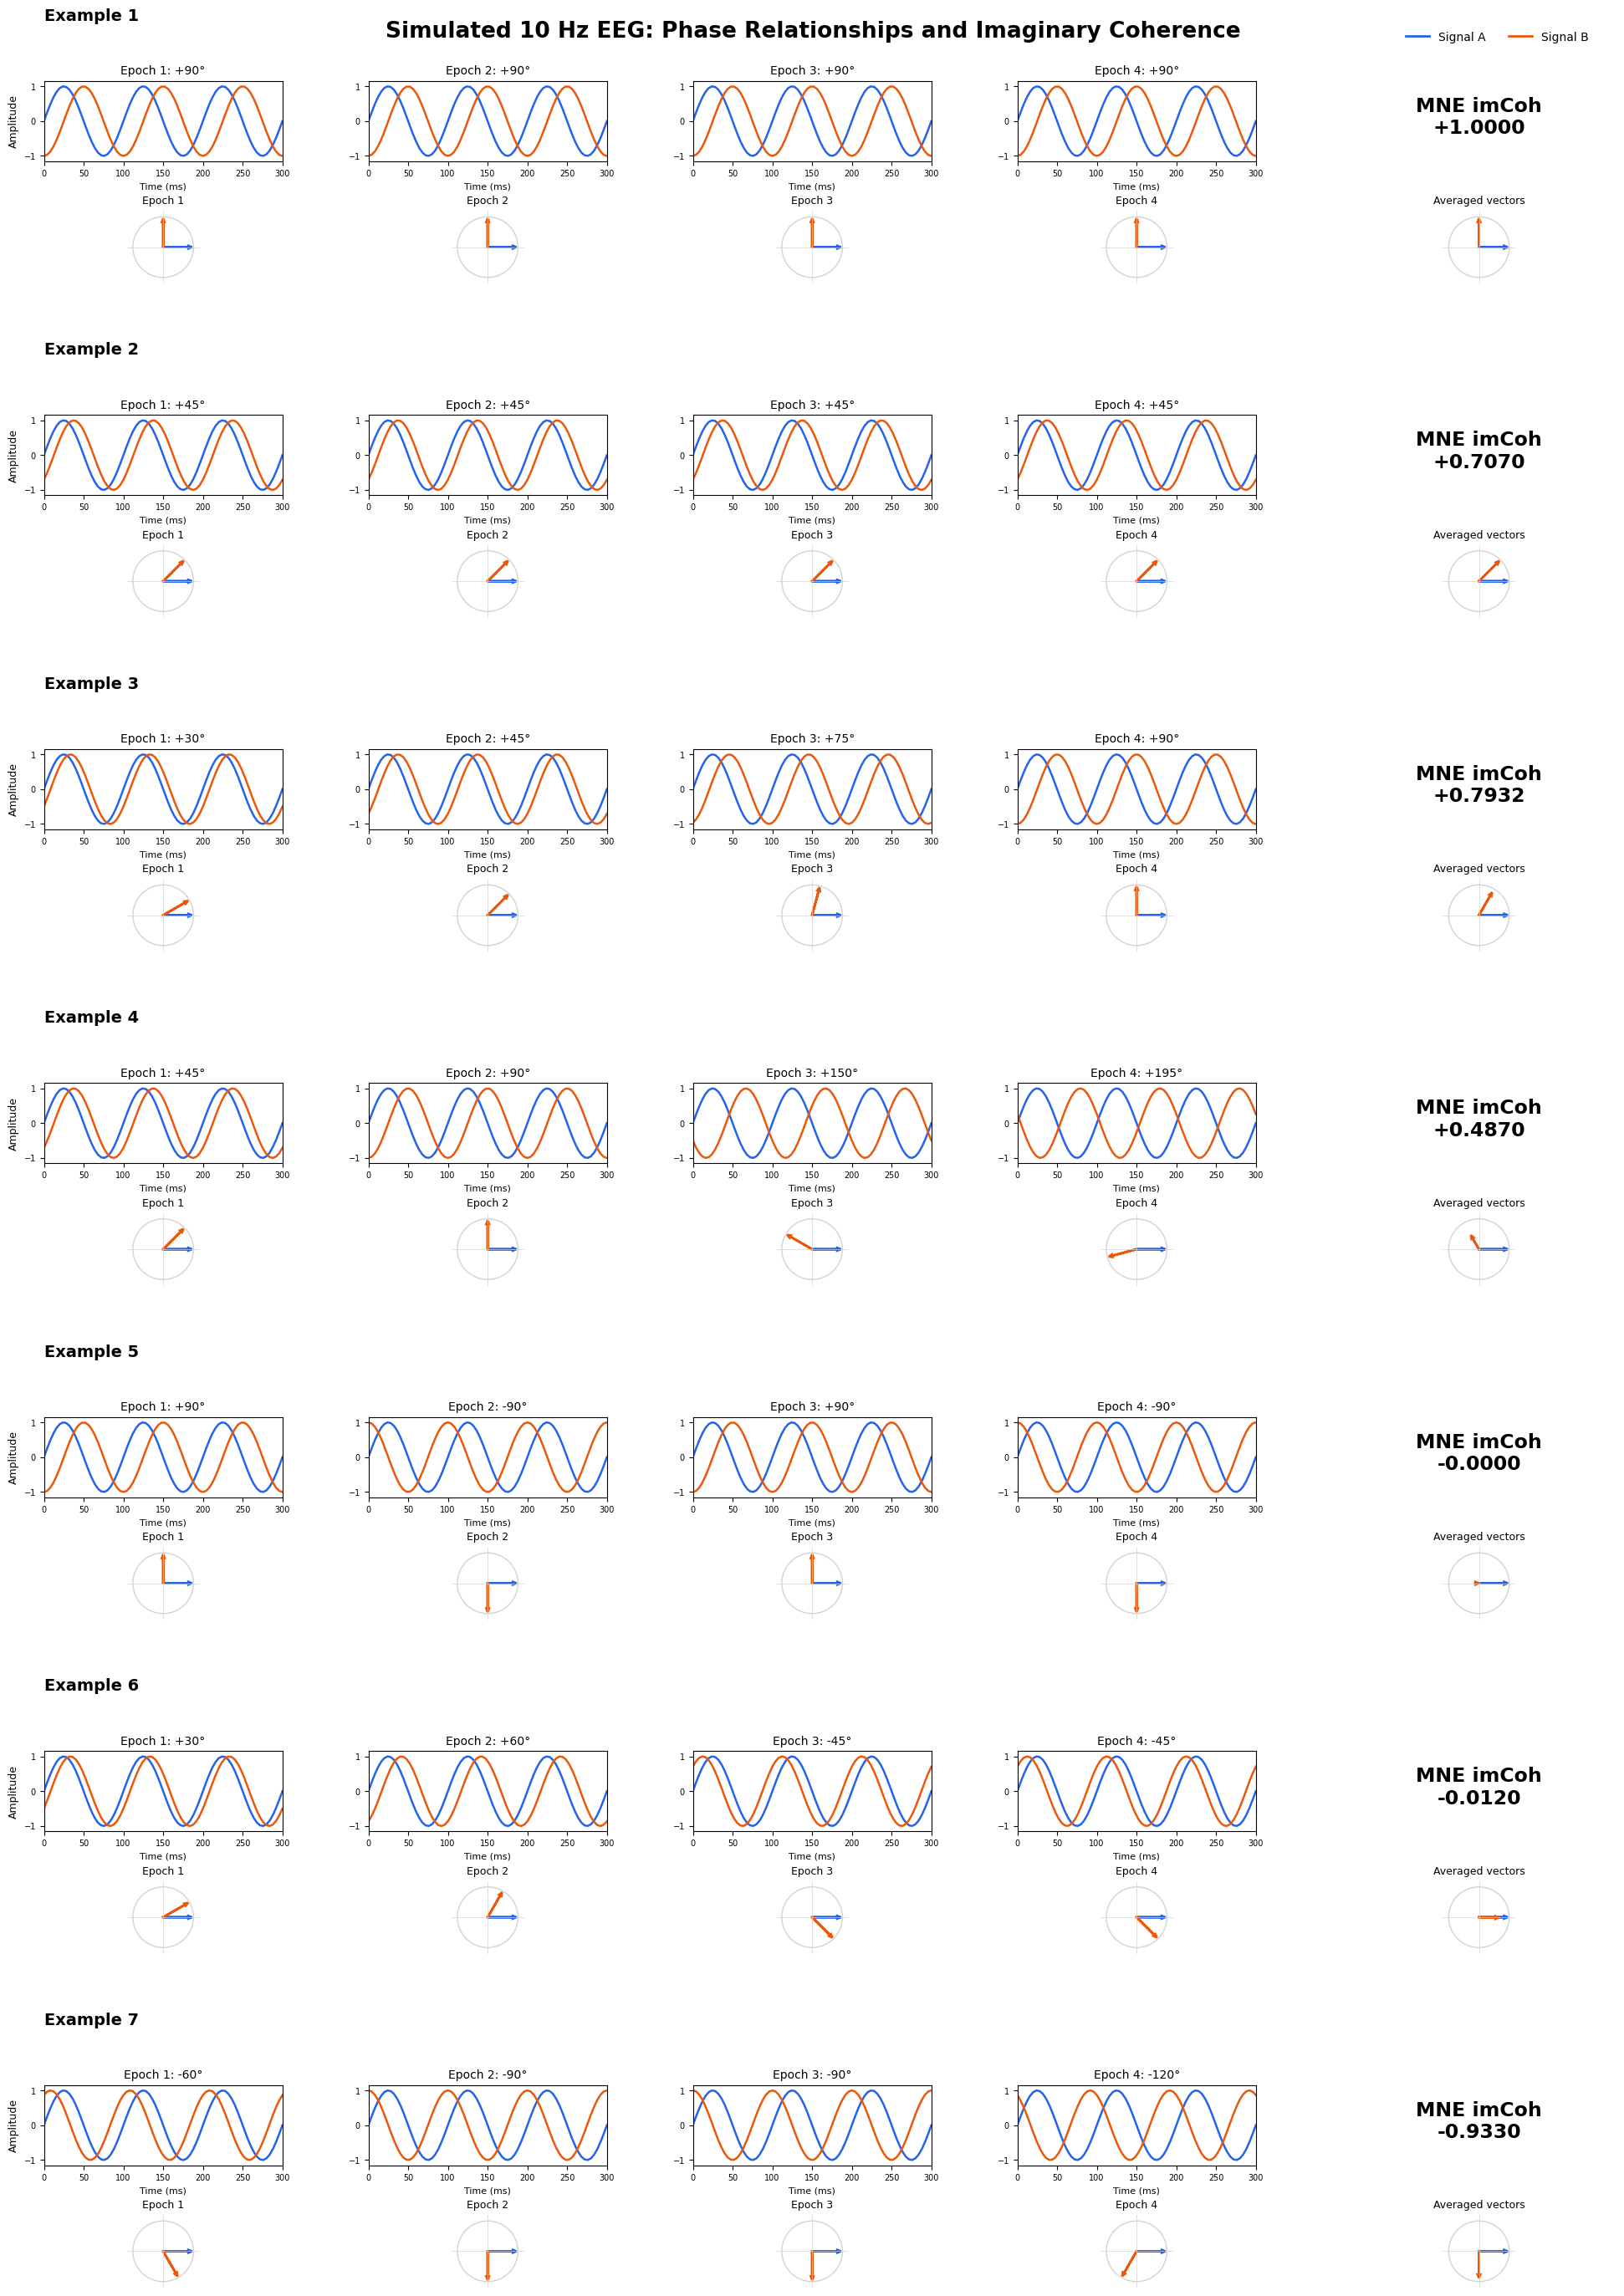

In [15]:
fig = plt.figure(figsize=(20, 29))
outer = fig.add_gridspec(
    7, 1, hspace=0.65,
    left=0.04, right=0.98, top=0.96, bottom=0.05
)

colors = ["#2563eb", "#ea580c"]
wave_duration = 0.3  #Display 300 ms from each 4-second epoch

for row, (name, epochs) in enumerate(simulated_epochs.items()):

    data = epochs.get_data()
    times = epochs.times
    phases = np.deg2rad(examples[name])
    imcoh = float(all_subject_connectivity[name][0, 0])

    inner = outer[row].subgridspec(
        2, 5,
        height_ratios=[1.1, 1],
        width_ratios=[1, 1, 1, 1, 1.15],
        hspace=0.65, wspace=0.35
    )

    #Four separate waveform observations
    for ep in range(4):
        ax = fig.add_subplot(inner[0, ep])

        mask = times <= wave_duration
        ax.plot(times[mask] * 1000, data[ep, 0, mask],
                color=colors[0], lw=1.8)
        ax.plot(times[mask] * 1000, data[ep, 1, mask],
                color=colors[1], lw=1.8)

        ax.set_title(
            f"Epoch {ep + 1}: {examples[name][ep]:+d}°",
            fontsize=10
        )
        ax.set_xlim(0, wave_duration * 1000)
        ax.set_ylim(-1.15, 1.15)
        ax.set_xlabel("Time (ms)", fontsize=8)
        ax.tick_params(labelsize=7)

        if ep == 0:
            ax.set_ylabel("Amplitude", fontsize=9)

    #Individual phase-vector pairs
    for ep in range(4):
        ax = fig.add_subplot(inner[1, ep])
        phi = phases[ep]

        circle = plt.Circle(
            (0, 0), 1, fill=False,
            color="lightgray", lw=1
        )
        ax.add_patch(circle)

        for angle, color in [(0, colors[0]), (phi, colors[1])]:
            ax.arrow(
                0, 0,
                np.cos(angle) * 0.95,
                np.sin(angle) * 0.95,
                head_width=0.09,
                head_length=0.12,
                length_includes_head=True,
                color=color,
                lw=2
            )

        ax.axhline(0, color="lightgray", lw=0.5)
        ax.axvline(0, color="lightgray", lw=0.5)
        ax.set_xlim(-1.2, 1.2)
        ax.set_ylim(-1.2, 1.2)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f"Epoch {ep + 1}", fontsize=9)

    #Two averaged signal-phase vectors
    ax = fig.add_subplot(inner[1, 4])

    mean_a = np.mean(np.exp(1j * np.zeros(4)))
    mean_b = np.mean(np.exp(1j * phases))

    circle = plt.Circle(
        (0, 0), 1, fill=False,
        color="lightgray", lw=1
    )
    ax.add_patch(circle)

    for vector, color in [(mean_a, colors[0]),
                          (mean_b, colors[1])]:
        ax.arrow(
            0, 0,
            vector.real * 0.95,
            vector.imag * 0.95,
            head_width=0.09,
            head_length=0.12,
            length_includes_head=True,
            color=color,
            lw=2
        )

    ax.axhline(0, color="lightgray", lw=0.5)
    ax.axvline(0, color="lightgray", lw=0.5)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Averaged vectors", fontsize=9)

    #MNE result
    result_ax = fig.add_subplot(inner[0, 4])
    result_ax.axis("off")
    result_ax.text(
        0.5, 0.55,
        f"MNE imCoh\n{imcoh:+.4f}",
        ha="center", va="center",
        fontsize=17, fontweight="bold",
        transform=result_ax.transAxes
    )

    fig.text(
        0.04, outer[row].get_position(fig).y1 + 0.025,
        name,
        fontsize=14, fontweight="bold"
    )

fig.suptitle(
    "Simulated 10 Hz EEG: Phase Relationships and Imaginary Coherence",
    fontsize=19, fontweight="bold", y=0.985
)

fig.legend(
    handles=[
        plt.Line2D([0], [0], color=colors[0], lw=2, label="Signal A"),
        plt.Line2D([0], [0], color=colors[1], lw=2, label="Signal B")
    ],
    loc="upper right", bbox_to_anchor=(0.97, 0.985),
    ncol=2, frameon=False
)

plt.savefig("/home/ekstrandlab/Desktop/simulated_imcoh_7_examples.png", dpi=300)
plt.show()